In [ ]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:

import os
import tarfile

archive_path = "/content/cifar-10-python.tar.gz"
extract_path = "/content"

if os.path.exists(archive_path):
    with tarfile.open(archive_path, "r:gz") as tar:
        tar.extractall(path=extract_path)

    print("Dataset extracted successfully!")
    print("Dataset folder exists:",
          os.path.isdir("/content/cifar-10-batches-py"))
else:
    print("Archive not found. Please check the uploaded filename.")


/tmp/ipykernel_827/3639752073.py:9: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_path)


Dataset extracted successfully!
Dataset folder exists: True


In [7]:

import os
import pickle
import numpy as np

data_dir = "/content/cifar-10-batches-py"

def load_batch(file_path):
    with open(file_path, "rb") as f:
        batch = pickle.load(f, encoding="bytes")

    images = batch[b"data"].reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1)
    labels = np.array(batch[b"labels"])

    return images, labels

# Load all five training batches
train_images = []
train_labels = []

for i in range(1, 6):
    images, labels = load_batch(
        os.path.join(data_dir, f"data_batch_{i}")
    )
    train_images.append(images)
    train_labels.append(labels)

x_train = np.concatenate(train_images)
y_train = np.concatenate(train_labels)

# Load test batch
x_test, y_test = load_batch(
    os.path.join(data_dir, "test_batch")
)

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)
print("Classes:", len(class_names))


Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Test images: (10000, 32, 32, 3)
Test labels: (10000,)
Classes: 10


In [8]:

import tensorflow as tf

SEED = 42
BATCH_SIZE = 128

tf.keras.utils.set_random_seed(SEED)

# Data augmentation for training images only
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
], name="data_augmentation")

def preprocess_train(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    images = data_augmentation(images, training=True)
    return images, labels

def preprocess_test(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

# Create training pipeline
train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(10000, seed=SEED)
    .batch(BATCH_SIZE)
    .map(preprocess_train, num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

# Create test pipeline
test_ds = (
    tf.data.Dataset.from_tensor_slices((x_test, y_test))
    .batch(BATCH_SIZE)
    .map(preprocess_test, num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

# Verify the pipeline
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", float(tf.reduce_min(images)))
    print("Maximum pixel value:", float(tf.reduce_max(images)))

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())


Image batch shape: (128, 32, 32, 3)
Label batch shape: (128,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Training batches: 391
Test batches: 79


In [9]:

import tensorflow as tf

SEED = 42
BATCH_SIZE = 128

tf.keras.utils.set_random_seed(SEED)

X_train = x_train
Y_train = y_train

X_test = x_test
Y_test = y_test

# Normalize images and augment training images
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
])

def preprocess_train(X, Y):
    X = tf.cast(X, tf.float32) / 255.0
    X = data_augmentation(X, training=True)
    return X, Y

def preprocess_test(X, Y):
    X = tf.cast(X, tf.float32) / 255.0
    return X, Y

# Training data pipeline
train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, Y_train))
    .shuffle(10000, seed=SEED)
    .batch(BATCH_SIZE)
    .map(preprocess_train, num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

# Testing data pipeline
test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, Y_test))
    .batch(BATCH_SIZE)
    .map(preprocess_test, num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

# Check one batch
for X, Y in train_ds.take(1):
    print("X batch shape:", X.shape)
    print("Y batch shape:", Y.shape)
    print("Minimum pixel value:", float(tf.reduce_min(X)))
    print("Maximum pixel value:", float(tf.reduce_max(X)))

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())


X batch shape: (128, 32, 32, 3)
Y batch shape: (128,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Training batches: 391
Testing batches: 79


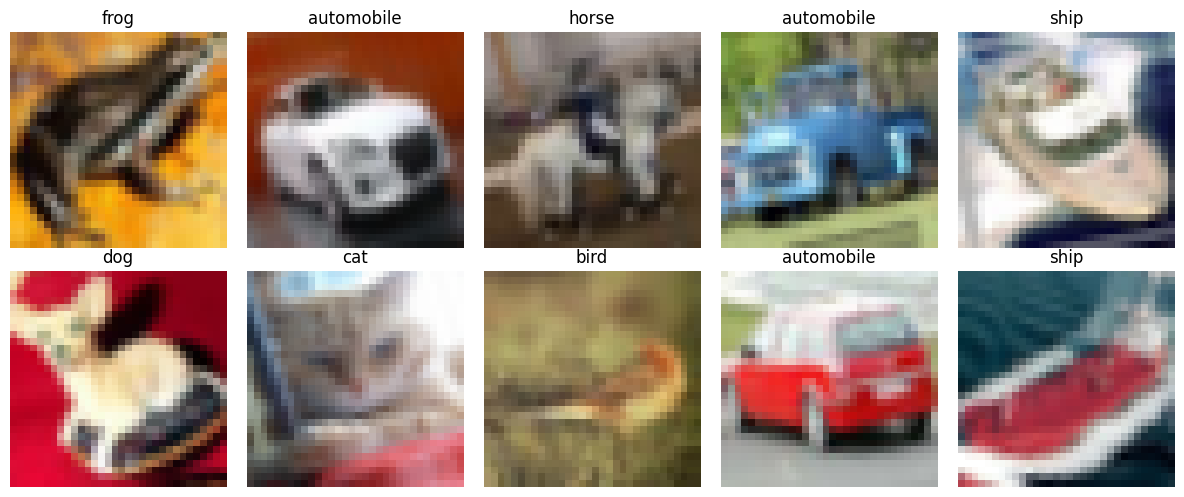

In [10]:

import matplotlib.pyplot as plt

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Get one batch of training images and labels
for X, Y in train_ds.take(1):
    images = X.numpy()
    labels = Y.numpy()

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i])
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [11]:

from tensorflow.keras import layers, models

def build_baseline_cnn():
    model = models.Sequential([
        layers.Input(shape=(32, 32, 3)),

        # Convolution block 1
        layers.Conv2D(32, 3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(32, 3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        # Convolution block 2
        layers.Conv2D(64, 3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(64, 3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.30),

        # Classification head
        layers.Flatten(),
        layers.Dense(128, use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.40),
        layers.Dense(10, activation="softmax")
    ])

    return model

baseline_model = build_baseline_cnn()
baseline_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 592,234 (2.26 MB)

 Trainable params: 591,594 (2.26 MB)

 Non-trainable params: 640 (2.50 KB)

In [12]:

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Baseline CNN compiled successfully!")
print("Number of classes:", baseline_model.output_shape[-1])


Baseline CNN compiled successfully!
Number of classes: 10


In [13]:

import tensorflow as tf
import os

# Split the original training data into training and validation sets
VAL_SIZE = 5000
BATCH_SIZE = 128
SEED = 42

X_fit = X_train[VAL_SIZE:]
Y_fit = Y_train[VAL_SIZE:]

X_val = X_train[:VAL_SIZE]
Y_val = Y_train[:VAL_SIZE]

def preprocess_validation(X, Y):
    X = tf.cast(X, tf.float32) / 255.0
    return X, Y

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_fit, Y_fit))
    .shuffle(10000, seed=SEED)
    .batch(BATCH_SIZE)
    .map(preprocess_train, num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, Y_val))
    .batch(BATCH_SIZE)
    .map(preprocess_validation, num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

# Create directory for checkpoints
os.makedirs("/content/checkpoints", exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/checkpoints/best_baseline.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    )
]

history_baseline = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)


Epoch 1/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.3798 - loss: 1.7737
Epoch 1: val_accuracy improved from None to 0.32560, saving model to /content/checkpoints/best_baseline.keras

Epoch 1: finished saving model to /content/checkpoints/best_baseline.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 30s 49ms/step - accuracy: 0.4534 - loss: 1.5314 - val_accuracy: 0.3256 - val_loss: 1.9635 - learning_rate: 0.0010
Epoch 2/10
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5601 - loss: 1.2273
Epoch 2: val_accuracy improved from 0.32560 to 0.57860, saving model to /content/checkpoints/best_baseline.keras

Epoch 2: finished saving model to /content/checkpoints/best_baseline.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.5770 - loss: 1.1824 - val_accuracy: 0.5786 - val_loss: 1.2088 - learning_rate: 0.0010
Epoch 3/10
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6224 - loss: 1.0700
Epoch 3: val_accuracy improved from 0.57860 to 0.63800, saving model to /conten

In [14]:

# Evaluate the best baseline model restored after training
test_loss, test_accuracy = baseline_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Baseline Test Loss: {test_loss:.4f}")
print(f"Baseline Test Accuracy: {test_accuracy * 100:.2f}%")


79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.7524 - loss: 0.7104
Baseline Test Loss: 0.7104
Baseline Test Accuracy: 75.24%


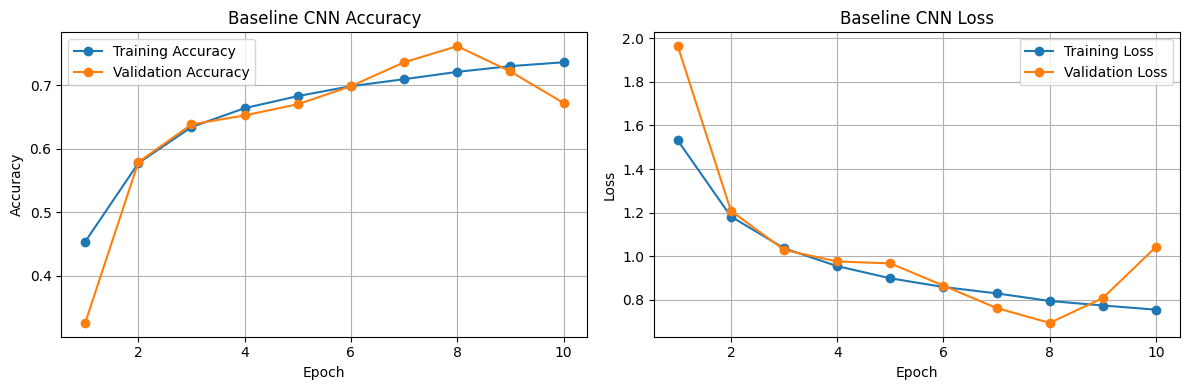

In [15]:

import matplotlib.pyplot as plt

history = history_baseline.history
epochs = range(1, len(history["loss"]) + 1)

plt.figure(figsize=(12, 4))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs, history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs, history["loss"], marker="o", label="Training Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
Misclassified images: 2476


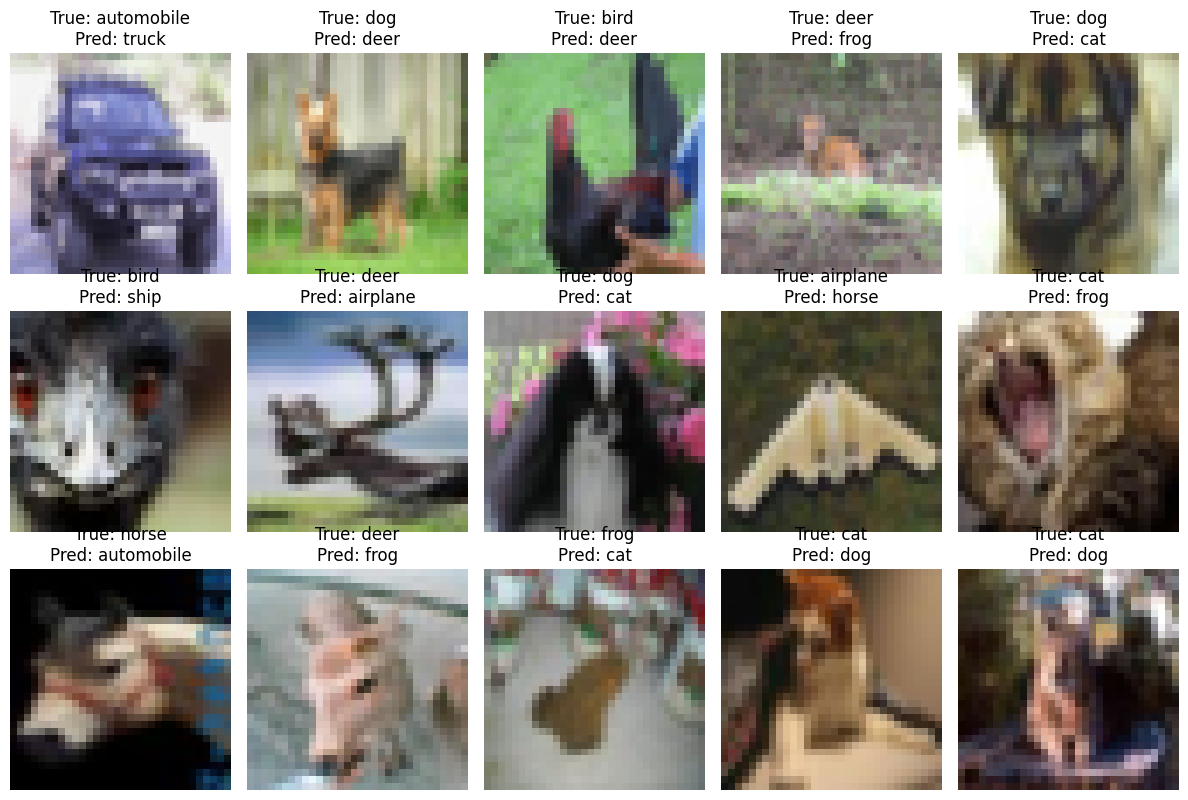

In [16]:

import numpy as np
import matplotlib.pyplot as plt

# Predict classes for the official test dataset
probabilities = baseline_model.predict(test_ds, verbose=1)
Y_pred = np.argmax(probabilities, axis=1)

# Find incorrectly classified images
wrong_indices = np.where(Y_pred != Y_test)[0]

print("Misclassified images:", len(wrong_indices))

plt.figure(figsize=(12, 8))

for plot_index, image_index in enumerate(wrong_indices[:15]):
    plt.subplot(3, 5, plot_index + 1)
    plt.imshow(X_test[image_index])
    plt.title(
        f"True: {class_names[Y_test[image_index]]}\n"
        f"Pred: {class_names[Y_pred[image_index]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


In [17]:

import os
import shutil

# Copy the best checkpoint to a convenient location
best_checkpoint = "/content/checkpoints/best_baseline.keras"
baseline_save_path = "/content/baseline_cnn.keras"

shutil.copy2(best_checkpoint, baseline_save_path)

print("Best baseline model saved at:", baseline_save_path)
print("File exists:", os.path.exists(baseline_save_path))


Best baseline model saved at: /content/baseline_cnn.keras
File exists: True


In [18]:

import tensorflow as tf
from tensorflow.keras import layers, Model

def residual_block(X, filters):
    shortcut = X

    X = layers.Conv2D(
        filters, 3, padding="same", use_bias=False
    )(X)
    X = layers.BatchNormalization()(X)
    X = layers.Activation("relu")(X)

    X = layers.Conv2D(
        filters, 3, padding="same", use_bias=False
    )(X)
    X = layers.BatchNormalization()(X)

    # Add the shortcut connection
    X = layers.Add()([X, shortcut])
    X = layers.Activation("relu")(X)

    return X


def build_residual_cnn():
    inputs = layers.Input(shape=(32, 32, 3))

    X = layers.Conv2D(
        32, 3, padding="same", use_bias=False
    )(inputs)
    X = layers.BatchNormalization()(X)
    X = layers.Activation("relu")(X)

    # Residual block with 32 feature channels
    X = residual_block(X, 32)

    X = layers.MaxPooling2D()(X)
    X = layers.Dropout(0.25)(X)

    X = layers.Conv2D(
        64, 3, padding="same", use_bias=False
    )(X)
    X = layers.BatchNormalization()(X)
    X = layers.Activation("relu")(X)

    X = layers.MaxPooling2D()(X)
    X = layers.Dropout(0.30)(X)

    X = layers.Flatten()(X)
    X = layers.Dense(128, activation="relu")(X)
    X = layers.Dropout(0.40)(X)
    outputs = layers.Dense(10, activation="softmax")(X)

    return Model(inputs, outputs, name="Residual_CNN")


residual_model = build_residual_cnn()
residual_model.summary()


Model: "Residual_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │        864 │ input_layer_3[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_5[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_6[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ activation_5[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_7        │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ activation_7[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 16, 16,    │          0 │ max_pooling2d_2[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │     18,432 │ dropout_3[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_7[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 64)  │          0 │ activation_8[0][

 Total params: 564,074 (2.15 MB)

 Trainable params: 563,754 (2.15 MB)

 Non-trainable params: 320 (1.25 KB)

In [19]:

residual_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Residual CNN compiled successfully!")


Residual CNN compiled successfully!


In [20]:

residual_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/checkpoints/best_residual.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    )
]

history_residual = residual_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=residual_callbacks
)


Epoch 1/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.1541 - loss: 2.4096
Epoch 1: val_accuracy improved from None to 0.19700, saving model to /content/checkpoints/best_residual.keras

Epoch 1: finished saving model to /content/checkpoints/best_residual.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 19s 35ms/step - accuracy: 0.1948 - loss: 2.1260 - val_accuracy: 0.1970 - val_loss: 2.1745 - learning_rate: 0.0010
Epoch 2/10
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.2669 - loss: 1.8851
Epoch 2: val_accuracy improved from 0.19700 to 0.39480, saving model to /content/checkpoints/best_residual.keras

Epoch 2: finished saving model to /content/checkpoints/best_residual.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - accuracy: 0.2703 - loss: 1.8672 - val_accuracy: 0.3948 - val_loss: 1.6523 - learning_rate: 0.0010
Epoch 3/10
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.2929 - loss: 1.8246
Epoch 3: val_accuracy did not improve from 0.39480
352/352 ━━━━━━━━━━━━━━━━━━━

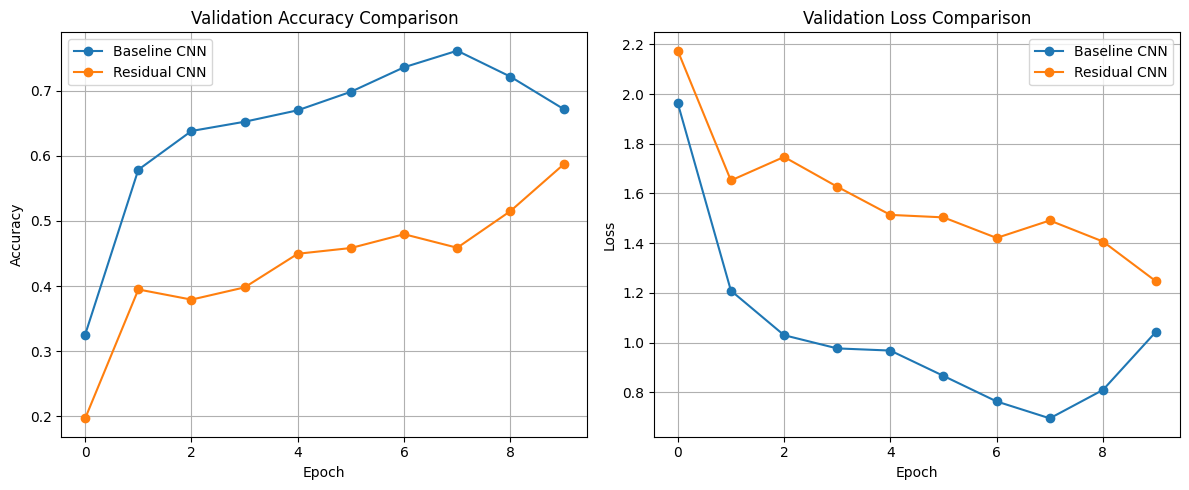

Baseline best validation accuracy: 76.12%
Residual best validation accuracy: 58.66%
Difference: -17.46 percentage points


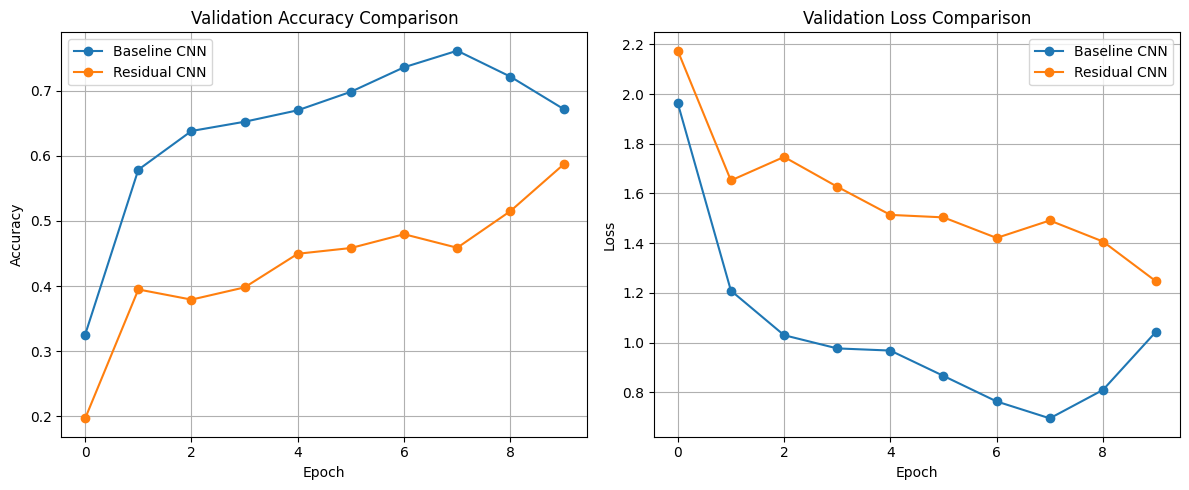

Baseline best validation accuracy: 76.12%
Residual best validation accuracy: 58.66%
Difference: -17.46 percentage points


In [21]:

import matplotlib.pyplot as plt

baseline_history = history_baseline.history
residual_history = history_residual.history

plt.figure(figsize=(12, 5))

# Validation accuracy
plt.subplot(1, 2, 1)
plt.plot(
    baseline_history["val_accuracy"],
    marker="o",
    label="Baseline CNN"
)
plt.plot(
    residual_history["val_accuracy"],
    marker="o",
    label="Residual CNN"
)
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Validation loss
plt.subplot(1, 2, 2)
plt.plot(
    baseline_history["val_loss"],
    marker="o",
    label="Baseline CNN"
)
plt.plot(
    residual_history["val_loss"],
    marker="o",
    label="Residual CNN"
)
plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

baseline_best_val = max(baseline_history["val_accuracy"])
residual_best_val = max(residual_history["val_accuracy"])

print(f"Baseline best validation accuracy: {baseline_best_val * 100:.2f}%")
print(f"Residual best validation accuracy: {residual_best_val * 100:.2f}%")
print(
    f"Difference: {(residual_best_val - baseline_best_val) * 100:+.2f} "
    "percentage points"
)

import matplotlib.pyplot as plt

baseline_history = history_baseline.history
residual_history = history_residual.history

plt.figure(figsize=(12, 5))

# Validation accuracy
plt.subplot(1, 2, 1)
plt.plot(
    baseline_history["val_accuracy"],
    marker="o",
    label="Baseline CNN"
)
plt.plot(
    residual_history["val_accuracy"],
    marker="o",
    label="Residual CNN"
)
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Validation loss
plt.subplot(1, 2, 2)
plt.plot(
    baseline_history["val_loss"],
    marker="o",
    label="Baseline CNN"
)
plt.plot(
    residual_history["val_loss"],
    marker="o",
    label="Residual CNN"
)
plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

baseline_best_val = max(baseline_history["val_accuracy"])
residual_best_val = max(residual_history["val_accuracy"])

print(f"Baseline best validation accuracy: {baseline_best_val * 100:.2f}%")
print(f"Residual best validation accuracy: {residual_best_val * 100:.2f}%")
print(
    f"Difference: {(residual_best_val - baseline_best_val) * 100:+.2f} "
    "percentage points"
)


In [22]:

residual_test_loss, residual_test_accuracy = residual_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Residual Test Loss: {residual_test_loss:.4f}")
print(f"Residual Test Accuracy: {residual_test_accuracy * 100:.2f}%")


79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.5896 - loss: 1.2403
Residual Test Loss: 1.2403
Residual Test Accuracy: 58.96%


In [23]:

residual_model.save("/content/residual_cnn.keras")
print("Residual model saved successfully.")


Residual model saved successfully.


In [24]:

baseline_test_loss, baseline_test_accuracy = baseline_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Baseline Test Loss: {baseline_test_loss:.4f}")
print(f"Baseline Test Accuracy: {baseline_test_accuracy * 100:.2f}%")


79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7524 - loss: 0.7104
Baseline Test Loss: 0.7104
Baseline Test Accuracy: 75.24%


In [25]:

from google.colab import files

files.download("/content/baseline_cnn.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:

files.download("/content/residual_cnn.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>